# From trigger to flood map: what was under water when the trigger paid?

**KAI-Hydro and KAI-River · Guadalquivir, Mengíbar to Andújar, Spain**

**Question.** Notebook 1 asked whether a parametric flood trigger set from global data would have paid in the right years. A policy holder, a lender or a civil-protection office also asks *what was under water*. This notebook takes the biggest flood in the Mengíbar gauge's record, water year 2010-11, and maps it on 54 km of the Guadalquivir below the gauge, to Andújar, once for each way of reading that year:

* **measured** at the gauge (CEDEX 5004, Mengíbar): the reference;
* **GloFAS 4.0** and **GloFAS 5.0**, read straight in m³/s;
* GloFAS 4.0, GloFAS 5.0 and **rainfall only** (the case's first index: NASA POWER catchment rainfall, as the October–April total and as the wettest 3 days), each read as a **return period** in its own record and turned into the flow of that return period on the gauge's curve, which is how a return-period trigger is written.

Each map comes from the SFINCS flood model (Deltares, open source under GNU GPL-3.0, built from source by KAI) on the Copernicus 30 m DEM with roughness from ESA WorldCover; the gauge's 10- and 100-year floods are then set beside the Copernicus global flood hazard map.

**Data.** All open: CEDEX *Anuario de Aforos 2021-2022* (gauge flows, via notebook 1's annual maxima); GloFAS 4.0 and 5.0 reanalyses (Copernicus Emergency Management Service); NASA POWER rainfall; Copernicus DEM GLO-30 (© DLR e.V. 2010-2014 and © Airbus Defence and Space GmbH 2014-2018, provided under COPERNICUS by the European Union and ESA); ESA WorldCover 2021 v200 (© ESA WorldCover project, CC BY 4.0); JRC/CEMS global river flood hazard maps v2.1 (© European Union, CC BY 4.0). `flood_maps.py` downloads the DEM, land cover and hazard map, checks them by SHA-256 (`flood_maps_files.sha256`), runs SFINCS and writes the depth maps in `data/flood_maps/` that this notebook reads.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio
from matplotlib.colors import ListedColormap
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 10.5, "legend.frameon": False,
                     "savefig.bbox": "tight", "savefig.facecolor": "white"})
GAUGE, MODEL, OK, AMBER, GREY, RAIN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781", "#7a5cc4"
res = json.loads(pathlib.Path("results/flood_maps.json").read_text())
S = {s["id"]: s for s in res["scenarios"]}

def depth(name):
    with rasterio.open(f"data/flood_maps/{name}_depth_dm.tif") as r:
        a = r.read(1); b = r.bounds
    inside = a != 255
    return np.where(inside, a / 10.0, np.nan), inside, (b.left, b.right, b.bottom, b.top)

base, MODEL_AREA, EXT = depth("base")
DRY = res["settings"]["flood_depth_m"]
def flooded(name):
    h, _, _ = depth(name)
    return (np.nan_to_num(h) >= DRY) & ~(np.nan_to_num(base) >= DRY)

towns = {"Mengíbar": (429_000, 4_202_700), "Espeluy": (424_350, 4_209_950),
         "Villanueva de la Reina": (419_750, 4_206_700), "Andújar": (407_800, 4_210_650)}
r = res["reach"]
print(f"{r['river_km']} km of river · {r['model_cells']:,} cells of 30 m · flood of water year {r['event_water_year'] - 1}-{str(r['event_water_year'])[2:]}")
pd.DataFrame(res["scenarios"])[["label", "index_value", "unit", "T", "q", "read_as", "pays_1in5"]].round(1)

54.2 km of river · 100,231 cells of 30 m · flood of water year 2010-11


,label,index_value,unit,T,q,read_as,pays_1in5
0,Measured at the gauge,591.2,m3/s,32.5,591.2,measured,True
1,"GloFAS 4.0, in m3/s",53.3,m3/s,6.0,53.3,m3/s,False
2,"GloFAS 5.0, in m3/s",381.6,m3/s,9.2,381.6,m3/s,True
3,"GloFAS 4.0, as a return period",53.3,m3/s,6.0,291.7,return period,True
4,"GloFAS 5.0, as a return period",381.6,m3/s,9.2,356.2,return period,True
5,"Rainfall only, Oct-Apr total",349.6,mm,8.5,344.5,return period,True
6,"Rainfall only, wettest 3 days",35.9,mm,2.0,139.0,return period,False
7,Gauge's 10-year flood,369.8,m3/s,10.0,369.8,design,None
8,Gauge's 100-year flood,872.7,m3/s,100.0,872.7,design,None
9,River in its banks,30.0,m3/s,NaN,30.0,base,None


## The year read seven ways

The gauge measured **591 m³/s** (daily mean) in 2010-11, about a 1-in-32-year flood on its own curve. GloFAS 4.0 put the same year at **53 m³/s**, GloFAS 5.0 at **382 m³/s**. As return periods in their own records, GloFAS 4.0 saw a 1-in-6 year, GloFAS 5.0 a 1-in-9, the October–April rainfall a 1-in-8.5 and the wettest 3 days a 1-in-2. The 1-in-5 trigger column is the trigger of notebook 1: the model's own 1-in-5 for a return-period trigger, the gauge's 1-in-5 flow (264 m³/s) for one written in m³/s.

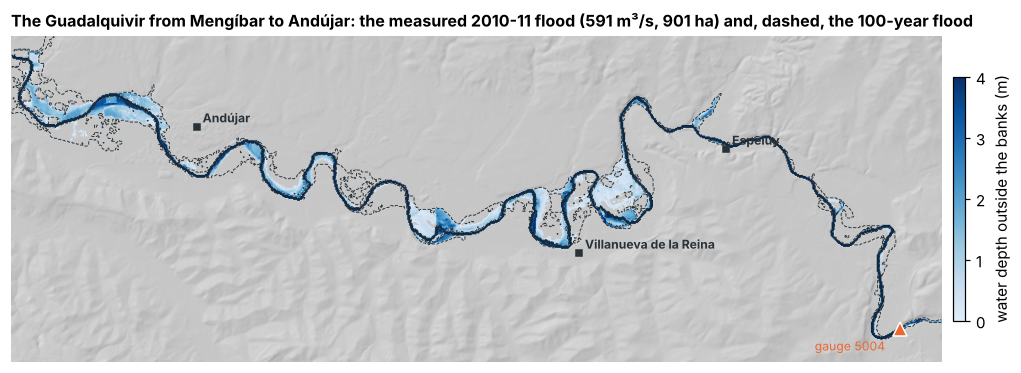

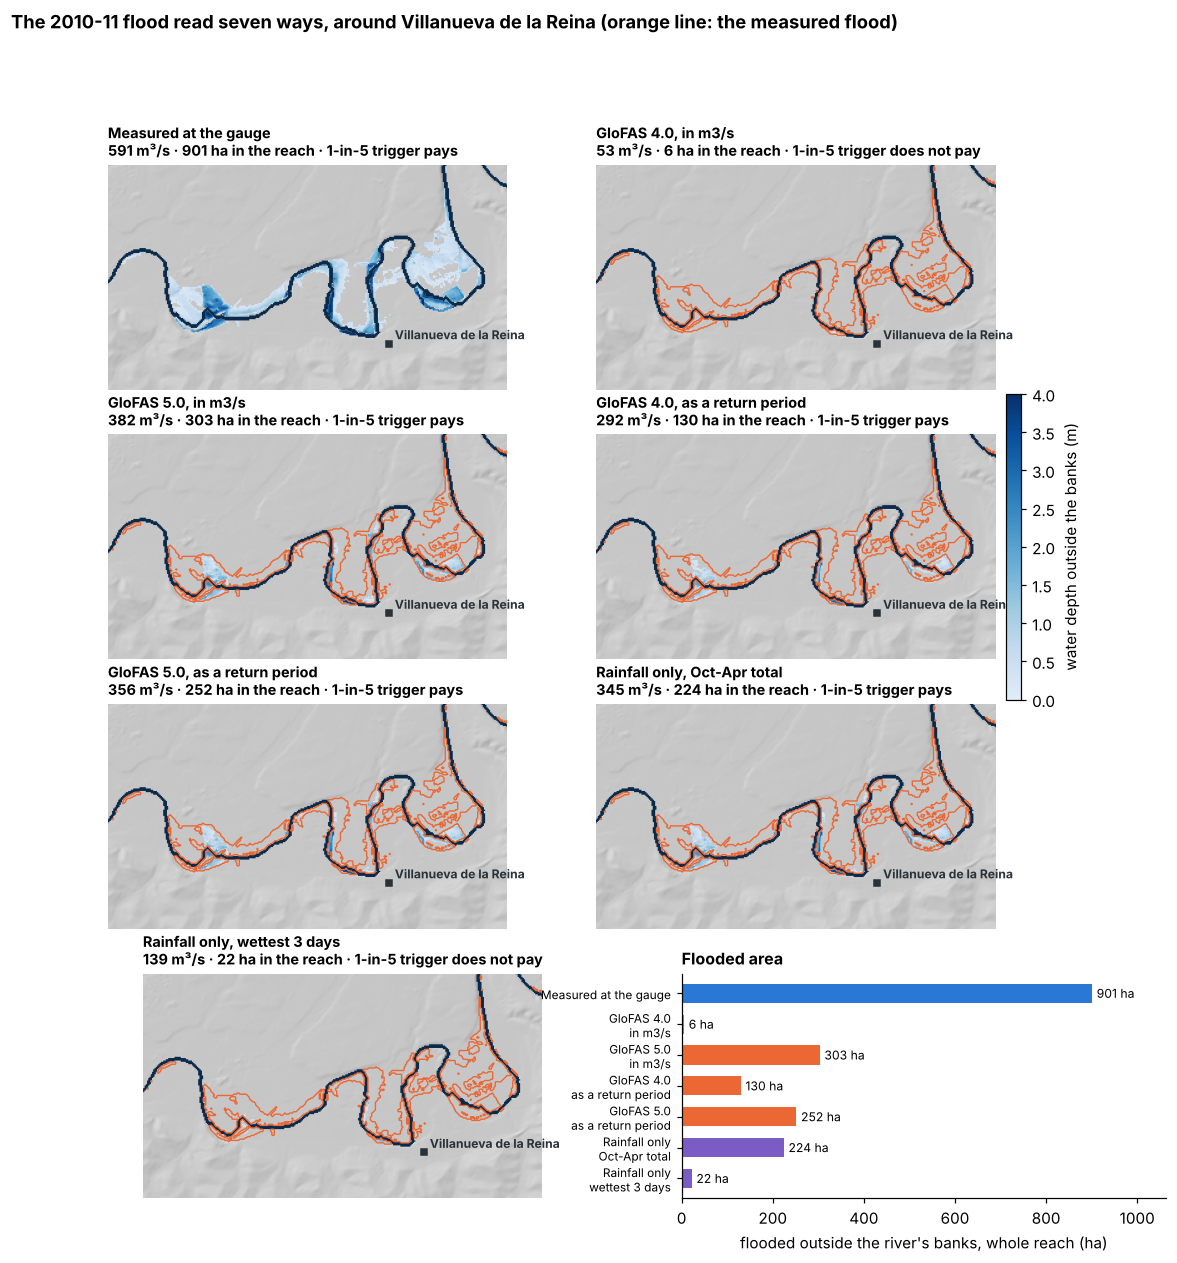

In [2]:
with rasterio.open("data/flood_maps/hillshade.tif") as r:
    HS = r.read(1).astype(float)
RIVER = np.nan_to_num(base) >= DRY
def panel(ax, name, title, window=None, outline=True, vmax=4):
    h, _, _ = depth(name)
    ax.imshow(HS, extent=EXT, cmap="gray", vmin=-60, vmax=300)
    ax.imshow(np.where(MODEL_AREA, 1.0, np.nan), extent=EXT, cmap=ListedColormap(["#ffffff"]), alpha=0.35)
    f = flooded(name)
    im = ax.imshow(np.where(f, h, np.nan), extent=EXT, cmap="Blues", vmin=-0.5, vmax=vmax)
    ax.imshow(np.where(RIVER, 1.0, np.nan), extent=EXT, cmap=ListedColormap(["#0b2a4a"]))
    if outline and name != "measured":
        ax.contour(flooded("measured").astype(float), levels=[0.5], colors=[MODEL], linewidths=0.9, extent=EXT, origin="upper")
    for t, (x, y) in towns.items():
        if window is None or (window[0] < x < window[1] and window[2] < y < window[3]):
            ax.plot(x, y, "s", ms=4, color="#283238"); ax.annotate(t, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=8, color="#283238", fontweight="bold")
    if window: ax.set_xlim(window[:2]); ax.set_ylim(window[2:])
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, loc="left", fontsize=9.5)
    for sp in ax.spines.values(): sp.set_visible(False)
    return im

# 1 · the whole reach, the measured flood
fig, ax = plt.subplots(figsize=(13, 4.8))
im = panel(ax, "measured", "", window=(402_000, 431_100, 4_203_300, 4_213_500), outline=False)
ax.contour(flooded("design_T100").astype(float), levels=[0.5], colors=["#283238"], linewidths=0.6, linestyles="--", extent=EXT, origin="upper")
gx, gy = 429_800, 4_204_330
ax.plot(gx, gy, "^", ms=9, color=MODEL, mec="white"); ax.annotate("gauge 5004", (gx, gy), xytext=(-10, -14), textcoords="offset points", fontsize=8, color=MODEL, ha="right")
ax.set_title(f"The Guadalquivir from Mengíbar to Andújar: the measured 2010-11 flood ({S['measured']['q']:.0f} m³/s, {S['measured']['flooded_ha']:,.0f} ha) and, dashed, the 100-year flood", loc="left")
cb = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.01, label="water depth outside the banks (m)"); cb.ax.set_ylim(0, 4)
fig.savefig("figures/gq_flood_reach.png", dpi=130); plt.show()

# 2 · seven readings of the same year, around Villanueva de la Reina
W = (413_000, 422_600, 4_205_600, 4_211_000)
order = ["measured", "v4_flow", "v5_flow", "v4_rp", "v5_rp", "rain_season", "rain_storm"]
fig, axs = plt.subplots(4, 2, figsize=(12.5, 12.2))
for ax, k in zip(axs.flat, order):
    s = S[k]
    tag = "trigger pays" if s["pays_1in5"] else "trigger does not pay"
    im = panel(ax, k, f"{s['label']}\n{s['q']:.0f} m³/s · {s['flooded_ha']:,.0f} ha in the reach · 1-in-5 {tag}", window=W)
ax = axs.flat[-1]
lab = [S[k]["label"].replace(", ", "\n") for k in order]
ha = [S[k]["flooded_ha"] for k in order]
cols = [GAUGE] + [MODEL] * 4 + [RAIN] * 2
ax.barh(range(len(order)), ha, color=cols, height=0.62); ax.set_yticks(range(len(order)), lab, fontsize=7.8); ax.invert_yaxis()
for i, v in enumerate(ha): ax.annotate(f"{v:,.0f} ha", (v, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_xlabel("flooded outside the river's banks, whole reach (ha)"); ax.set_title("Flooded area", loc="left"); ax.set_xlim(0, 1.18 * max(ha))
cb = fig.colorbar(im, ax=axs[:3, :], shrink=0.4, pad=0.01, label="water depth outside the banks (m)"); cb.ax.set_ylim(0, 4)
fig.suptitle("The 2010-11 flood read seven ways, around Villanueva de la Reina (orange line: the measured flood)", x=0.06, y=0.995, ha="left", fontweight="bold")
fig.savefig("figures/gq_flood_maps.png", dpi=130); plt.show()

## How much of the flood each index saw

*Share of measured flood mapped* is the part of the measured flood's area that each map also floods. Land under water is split by ESA WorldCover class; olive groves are mapped as tree cover.

In [3]:
rows = []
for k in order:
    s = S[k]; v = s.get("vs_measured", {})
    e = s["exposure_ha"]
    rows.append({"index": s["label"], "read as": s["read_as"], "return period": round(s["T"], 1), "flow m³/s": round(s["q"]),
                 "1-in-5 trigger": "pays" if s["pays_1in5"] else "no", "flooded ha": s["flooded_ha"],
                 "share of measured flood mapped": None if v.get("hit_rate") is None else round(100 * v["hit_rate"]),
                 "cropland ha": e.get("Cropland", 0), "olive groves and trees ha": e.get("Trees (mostly olive groves)", 0),
                 "built-up ha": e.get("Built-up", 0)})
table = pd.DataFrame(rows).set_index("index"); table.to_csv("results/flood_maps_by_index.csv"); table

,read as,return period,flow m³/s,1-in-5 trigger,flooded ha,share of measured flood mapped,cropland ha,olive groves and trees ha,built-up ha
index,,,,,,,,,
Measured at the gauge,measured,32.5,591,pays,901.0,100,415.2,430.9,2.4
"GloFAS 4.0, in m3/s",m3/s,6.0,53,no,5.5,1,0.1,2.0,0.0
"GloFAS 5.0, in m3/s",m3/s,9.2,382,pays,303.3,34,85.9,191.6,1.1
"GloFAS 4.0, as a return period",return period,6.0,292,pays,130.1,14,31.0,81.7,0.6
"GloFAS 5.0, as a return period",return period,9.2,356,pays,252.0,28,73.2,155.4,0.9
"Rainfall only, Oct-Apr total",return period,8.5,345,pays,224.5,25,65.2,137.6,0.9
"Rainfall only, wettest 3 days",return period,2.0,139,no,22.3,2,3.5,13.2,0.1


## Is the flood model right? The 10- and 100-year floods against Copernicus's map

The same model at the gauge's 10-year and 100-year floods, beside the Copernicus (JRC) global river flood hazard map for the same return periods. That map is itself a model (LISFLOOD-FP at 90 m), not an observation; Spain's official flood-zone maps (SNCZI, MITECO) are the next check.

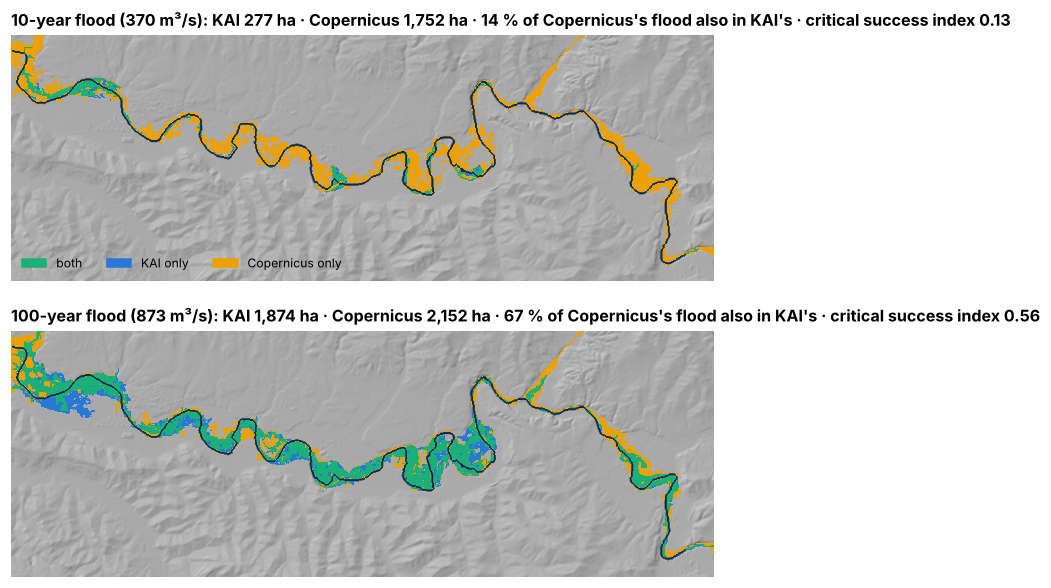

,jrc_flooded_ha,kai_flooded_ha,hit_rate,false_share,csi
T10,1751.7,276.8,0.14,0.14,0.13
T100,2152.5,1873.9,0.67,0.23,0.56


In [4]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6.4))
for ax, rp in zip(axs, (10, 100)):
    ours = flooded(f"design_T{rp}")
    h, _, _ = depth(f"jrc_T{rp}")
    jrc = (np.nan_to_num(h) >= DRY) & MODEL_AREA & ~(np.nan_to_num(base) >= DRY)
    cat = np.full(ours.shape, np.nan)
    cat[ours & jrc] = 1; cat[ours & ~jrc] = 2; cat[~ours & jrc] = 3
    ax.imshow(HS, extent=EXT, cmap="gray", vmin=-60, vmax=300)
    ax.imshow(np.where(RIVER, 1.0, np.nan), extent=EXT, cmap=ListedColormap(["#0b2a4a"]))
    ax.imshow(cat, extent=EXT, cmap=ListedColormap([OK, GAUGE, AMBER]), vmin=0.5, vmax=3.5, interpolation="nearest")
    c = res["jrc_check"][f"T{rp}"]
    ax.set_title(f"{rp}-year flood ({S[f'design_T{rp}']['q']:.0f} m³/s): KAI {c['kai_flooded_ha']:,.0f} ha · Copernicus {c['jrc_flooded_ha']:,.0f} ha · "
                 f"{100 * c['hit_rate']:.0f} % of Copernicus's flood also in KAI's · critical success index {c['csi']:.2f}", loc="left")
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
from matplotlib.patches import Patch
axs[0].legend(handles=[Patch(color=OK, label="both"), Patch(color=GAUGE, label="KAI only"), Patch(color=AMBER, label="Copernicus only")],
              loc="lower left", ncol=3, fontsize=8)
fig.savefig("figures/gq_flood_check.png", dpi=130); plt.show()
pd.DataFrame(res["jrc_check"]).T.round(2)

In [5]:
meas = S["measured"]
assert all(s["steady_check_m"] < 0.5 for s in res["scenarios"]), "a run had not settled"
assert S["v4_flow"]["flooded_ha"] < 0.25 * meas["flooded_ha"], "GloFAS 4.0 in m³/s should map a small part of the flood"
assert S["rain_storm"]["flooded_ha"] < S["rain_season"]["flooded_ha"] < meas["flooded_ha"]
assert all(S[a]["flooded_ha"] <= S[b]["flooded_ha"] + 1 for a, b in [("base", "rain_storm"), ("v4_rp", "v5_rp"), ("design_T10", "design_T100")])
summary = {k: {"q_m3s": round(S[k]["q"], 1), "T": None if S[k]["T"] is None else round(S[k]["T"], 1), "flooded_ha": S[k]["flooded_ha"],
               "hit_rate": S[k].get("vs_measured", {}).get("hit_rate")} for k in order}
print(json.dumps(summary, indent=1))

{
 "measured": {
  "q_m3s": 591.2,
  "T": 32.5,
  "flooded_ha": 901.0,
  "hit_rate": 1.0
 },
 "v4_flow": {
  "q_m3s": 53.3,
  "T": 6.0,
  "flooded_ha": 5.5,
  "hit_rate": 0.006093297372889822
 },
 "v5_flow": {
  "q_m3s": 381.6,
  "T": 9.2,
  "flooded_ha": 303.3,
  "hit_rate": 0.33662970732194586
 },
 "v4_rp": {
  "q_m3s": 291.7,
  "T": 6.0,
  "flooded_ha": 130.1,
  "hit_rate": 0.14444111477374888
 },
 "v5_rp": {
  "q_m3s": 356.2,
  "T": 9.2,
  "flooded_ha": 252.0,
  "hit_rate": 0.2796923384277295
 },
 "rain_season": {
  "q_m3s": 344.5,
  "T": 8.5,
  "flooded_ha": 224.5,
  "hit_rate": 0.2492258515632804
 },
 "rain_storm": {
  "q_m3s": 139.0,
  "T": 2.0,
  "flooded_ha": 22.3,
  "hit_rate": 0.02477274997502747
 }
}


## What it means

* **The flood came in at 591 m³/s, a 1-in-32 year, and covered about 900 ha of the valley floor below Mengíbar**, almost all of it farmland: some 415 ha of cropland and 430 ha of olive groves and other trees.
* **GloFAS 4.0 in m³/s missed it on the ground as well as in the contract.** At 53 m³/s the river stays in its banks (6 ha). GloFAS 5.0 in m³/s maps a third of the flood (303 ha).
* **Every index that paid called the year a 1-in-6 to a 1-in-9; on the ground that is 130 to 300 ha, not 900.** Between a 1-in-9 and a 1-in-32 flood the Guadalquivir leaves its incised channel and fills the meander lobes, so the flooded area grows three to seven times. A trigger that only has to say *yes* got the year right; a payout that steps up with the index would have paid for a flood a quarter of the size. The index has to get the size right, not just the year.
* **Rainfall only:** the October–April total read the year as well as the river indices did (1-in-8.5, 224 ha); the wettest 3 days did not pay (1-in-2, 22 ha). The 2010-11 flood came from a long wet winter, not from one storm, as notebook 1 found for flood years in this basin.
* **The flood model at the 10- and 100-year floods:** against Copernicus's global map the two agree on two-thirds of the 100-year flood (critical success index 0.56). At the 10-year flood Copernicus floods six times more land: at 90 m its map cannot see a channel 60 m wide cut several metres into the valley, so its river leaves the banks at every return period (1,750 ha at 1-in-10, 2,150 ha at 1-in-100). Spain's official flood-zone maps (SNCZI) are the check that settles it; `flood_maps.py` runs it when the two SNCZI zips are in `map_cache/`.
* **Limits.** Daily mean flows (instantaneous peaks are higher, so maps are on the small side); the Copernicus DEM is a surface model, so tree canopy within 300 m of the river is taken out with a 210 m grey opening (1.4 m on average over 13,158 cells) and buildings stay in; it holds no riverbed, so a 1.5 m channel is burnt below its water surface; tributaries below Mengíbar (Rumblar, Jándula) are left out; steady flows held for 48 hours rather than the event's hydrograph; one reach, one year.

**In KAI.** [KAI-Hydro](https://www.kaiwaterenergy.com/kai-hydro) writes and tests the trigger; [KAI-River](https://www.kaiwaterenergy.com/kai-river) maps the flood behind it with open flood models on public data, for any reach a client picks.

*References:* Leijnse, T. et al. (2021) Modeling compound flooding in coastal systems using a computationally efficient reduced-physics solver (SFINCS), *Coastal Engineering* 163, 103796 · European Commission, Joint Research Centre (2024) Global river flood hazard maps, version 2.1, Copernicus Emergency Management Service · Harrigan, S. et al. (2020), *Earth Syst. Sci. Data* 12, 2043–2060.